# Challenge: Edit MNIST challenge images to be correctly predicted

Goal: Edit the images placed in `data/MNIST/challenge` so that the provided model predicts the correct label while keeping more than 60% of the original pixels unchanged.

Description: You are given a pre-trained `SmallCNN` model and a small set of challenge images. Your task is to minimally modify these images so the model classifies them correctly. This exercise encourages you to: 
- Explore the sample dataset in `data/MNIST/sample` to understand variation and typical inputs.
- Use explainable AI (XAI) techniques (saliency maps, Grad-CAM, Integrated Gradients, occlusion, etc.) to discover what parts of the image the model relies on.
- Propose minimal edits (pixel changes, small masks, subtle color shifts) that change model prediction while preserving at least 60% of the original pixels.

Deliverables: For each edited image, save the modified image to `data/MNIST/challenge/edited/` alongside a short report (less than 2 pages) describing the XAI insights you used and the percentage of pixels preserved. For ease of use, you have the images already in that folder and you can directly work on them. You are allowed to use any external program you want to modify the image (i.e., paint, photoshop, figma, ...).

The practice can be done by more than 1 person. Final grade would depend on the number of images correctly edited (n_images_correct) with their corresponding report and number of persons working together (n_persons) following the next formula:
$$grade = 2,5 \times n\_images\_correct - 2,5 * (n\_persons - 1)$$


In [1]:
# Imports and device
import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


In [2]:
# SmallCNN definition (must match the trained model architecture)
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 12, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2,2)
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(12*7*7, 12)
        self.fc2 = nn.Linear(12, num_classes)

    def forward(self, x):
        x = self.pool(torch.nn.functional.relu(self.conv1(x)))  # 14x14
        x = self.pool(x)                      # 7x7
        x = x.view(x.size(0), -1)
        x = self.dropout(torch.nn.functional.relu(self.fc1(x)))
        return self.fc2(x)

# convenience transform
to_tensor = transforms.ToTensor()
to_pil = transforms.ToPILImage()

In [3]:
models_dir = Path('../models')
model_name = models_dir / 'small_cnn.pth'
model = torch.load(model_name, weights_only=False, map_location=device)
model.to(device) 
model.eval()

SmallCNN(
  (conv1): Conv2d(3, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=588, out_features=12, bias=True)
  (fc2): Linear(in_features=12, out_features=10, bias=True)
)

0_label5.png: Pred: 1, Label: 5
1_label3.png: Pred: 1, Label: 3
2_label3.png: Pred: 1, Label: 3
3_label7.png: Pred: 3, Label: 7
4_label2.png: Pred: 6, Label: 2


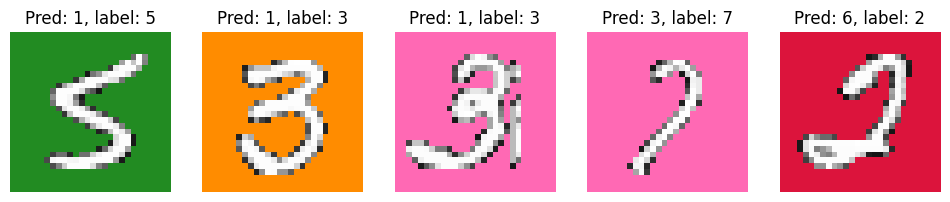

In [4]:
# Load the images in data/MNIST/challenge/ and plot them. Label of the image is the last character of the filename.
challenge_dir = Path('../data/MNIST/challenge')
image_files = list(challenge_dir.glob('*.png'))
fig, axes = plt.subplots(1, len(image_files), figsize=(12,4))
for ax, img_file in zip(axes, image_files):
    img = to_tensor(Image.open(img_file)).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img)
        pred = output.argmax(dim=1).item()
    ax.imshow(to_pil(img.squeeze().cpu()))
    ax.set_title(f'Pred: {pred}, label: {img_file.stem[-1]}')
    ax.axis('off')
    print(f'{img_file.name}: Pred: {pred}, Label: {img_file.stem[-1]}')
plt.show()

---
### Any code you want to add, put it below this markdown cell

## 1. Exploración del conjunto `sample`: ¿qué ha aprendido realmente el modelo?

Cada imagen es un dígito MNIST en escala de grises pintado sobre un **fondo de color uniforme**. Antes de tocar nada
medimos el color de fondo (píxel de la esquina), qué etiquetas aparecen con cada color y la precisión del modelo por color y por clase.

In [5]:
# ---------- 1. Sample-set exploration ----------
import copy
import numpy as np
import torch.nn.functional as F

cpu_model = copy.deepcopy(model).cpu().eval()  # analysis on CPU so that the search below is deterministic
report_dir = Path('../report')
report_dir.mkdir(exist_ok=True)

COLOR_NAMES = {(34, 139, 34): 'forestgreen', (255, 140, 0): 'darkorange', (255, 105, 180): 'hotpink',
               (220, 20, 60): 'crimson', (30, 144, 255): 'dodgerblue', (148, 0, 211): 'darkviolet'}
ODD_COLORS = ['forestgreen', 'darkorange', 'hotpink']

def to_batch(arrs):
    return torch.from_numpy(np.ascontiguousarray(np.stack(arrs))).permute(0, 3, 1, 2).float().div(255).contiguous()

def forward_with_fc1(x):
    # fc1 pre-activations (before the ReLU) and logits, eval mode
    with torch.no_grad():
        h = cpu_model.pool(cpu_model.pool(F.relu(cpu_model.conv1(x))))
        z = cpu_model.fc1(h.reshape(h.shape[0], -1))
        return z, cpu_model.fc2(F.relu(z))

sample_files = sorted(Path('../data/MNIST/sample').glob('*.png'))
X = np.stack([np.array(Image.open(f).convert('RGB')) for f in sample_files])
y = np.array([int(f.stem[-1]) for f in sample_files])
bg_s = np.array([COLOR_NAMES[tuple(int(v) for v in img[0, 0])] for img in X])
z_s, logits_s = forward_with_fc1(to_batch(X))
pred_s = logits_s.argmax(1).numpy()

print(f'Accuracy on the sample set: {(pred_s == y).mean():.3f}\n')
print(f'{"background":12s} {"n":>5s}  {"labels present":16s} {"accuracy":>8s}  most frequent predictions')
for name in COLOR_NAMES.values():
    idx = bg_s == name
    preds, counts = np.unique(pred_s[idx], return_counts=True)
    top = ', '.join(f'{p}:{c}' for p, c in sorted(zip(preds, counts), key=lambda t: -t[1])[:4])
    print(f'{name:12s} {idx.sum():5d}  {str(sorted(set(y[idx].tolist()))):16s} {(pred_s[idx] == y[idx]).mean():8.3f}  {top}')
print()
for c in range(10):
    print(f'class {c}: recall {(pred_s[y == c] == c).mean():.3f} | predicted {int((pred_s == c).sum()):4d} times')

Accuracy on the sample set: 0.720

background       n  labels present   accuracy  most frequent predictions
forestgreen   1722  [1, 3, 5, 7, 9]     0.506  1:1000, 9:384, 7:304, 3:34
darkorange    1708  [1, 3, 5, 7, 9]     0.470  1:1013, 9:432, 7:240, 3:23
hotpink       1644  [1, 3, 5, 7, 9]     0.509  1:972, 9:332, 7:310, 3:25
crimson       1712  [0, 2, 4, 6, 8]     0.946  2:381, 0:370, 8:328, 6:324
dodgerblue    1615  [0, 2, 4, 6, 8]     0.955  4:343, 6:336, 0:325, 2:309
darkviolet    1599  [0, 2, 4, 6, 8]     0.953  2:347, 4:340, 0:316, 8:306

class 0: recall 0.978 | predicted 1011 times
class 1: recall 0.995 | predicted 2985 times
class 2: recall 0.942 | predicted 1037 times
class 3: recall 0.020 | predicted   82 times
class 4: recall 0.974 | predicted  992 times
class 5: recall 0.000 | predicted    2 times
class 6: recall 0.943 | predicted  952 times
class 7: recall 0.568 | predicted  854 times
class 8: recall 0.920 | predicted  937 times
class 9: recall 0.771 | predicted 1148 time

**Conclusión.** El color de fondo codifica la **paridad** del dígito: verde/naranja/rosa → impares (1, 3, 5, 7, 9) y
carmesí/azul/violeta → pares (0, 2, 4, 6, 8). El modelo ha aprendido este atajo (*shortcut learning*): acierta ~95 % en los
fondos "pares" pero sólo ~50 % en los "impares", donde casi únicamente predice 1, 7 o 9. La clase **5 no se predice
prácticamente nunca** y la 3 casi nunca. Las imágenes del reto son justo un 5, dos 3, un 7 (los tres casos difíciles) y un 2.

## 2. Mapas de atribución clásicos: saliency, Integrated Gradients, Grad-CAM y oclusión

Mapas respecto a la **etiqueta correcta** de cada imagen del reto. IG se calcula con dos líneas base (negra y blanca);
la oclusión usa un parche negro 4×4 y mide cuánto cae el logit de la etiqueta.

0_label5.png: pred 1, label 5 | max |map|: |saliency|=0.000, IG (black baseline)=0.197, IG (white baseline)=0.000, Grad-CAM (conv1)=0.000, occlusion 4x4=0.000
1_label3.png: pred 1, label 3 | max |map|: |saliency|=0.000, IG (black baseline)=0.249, IG (white baseline)=0.000, Grad-CAM (conv1)=0.000, occlusion 4x4=0.000


2_label3.png: pred 1, label 3 | max |map|: |saliency|=0.000, IG (black baseline)=0.543, IG (white baseline)=0.000, Grad-CAM (conv1)=0.000, occlusion 4x4=0.204
3_label7.png: pred 3, label 7 | max |map|: |saliency|=0.458, IG (black baseline)=0.590, IG (white baseline)=0.064, Grad-CAM (conv1)=0.003, occlusion 4x4=0.992


4_label2.png: pred 6, label 2 | max |map|: |saliency|=1.253, IG (black baseline)=0.909, IG (white baseline)=0.137, Grad-CAM (conv1)=0.019, occlusion 4x4=1.294


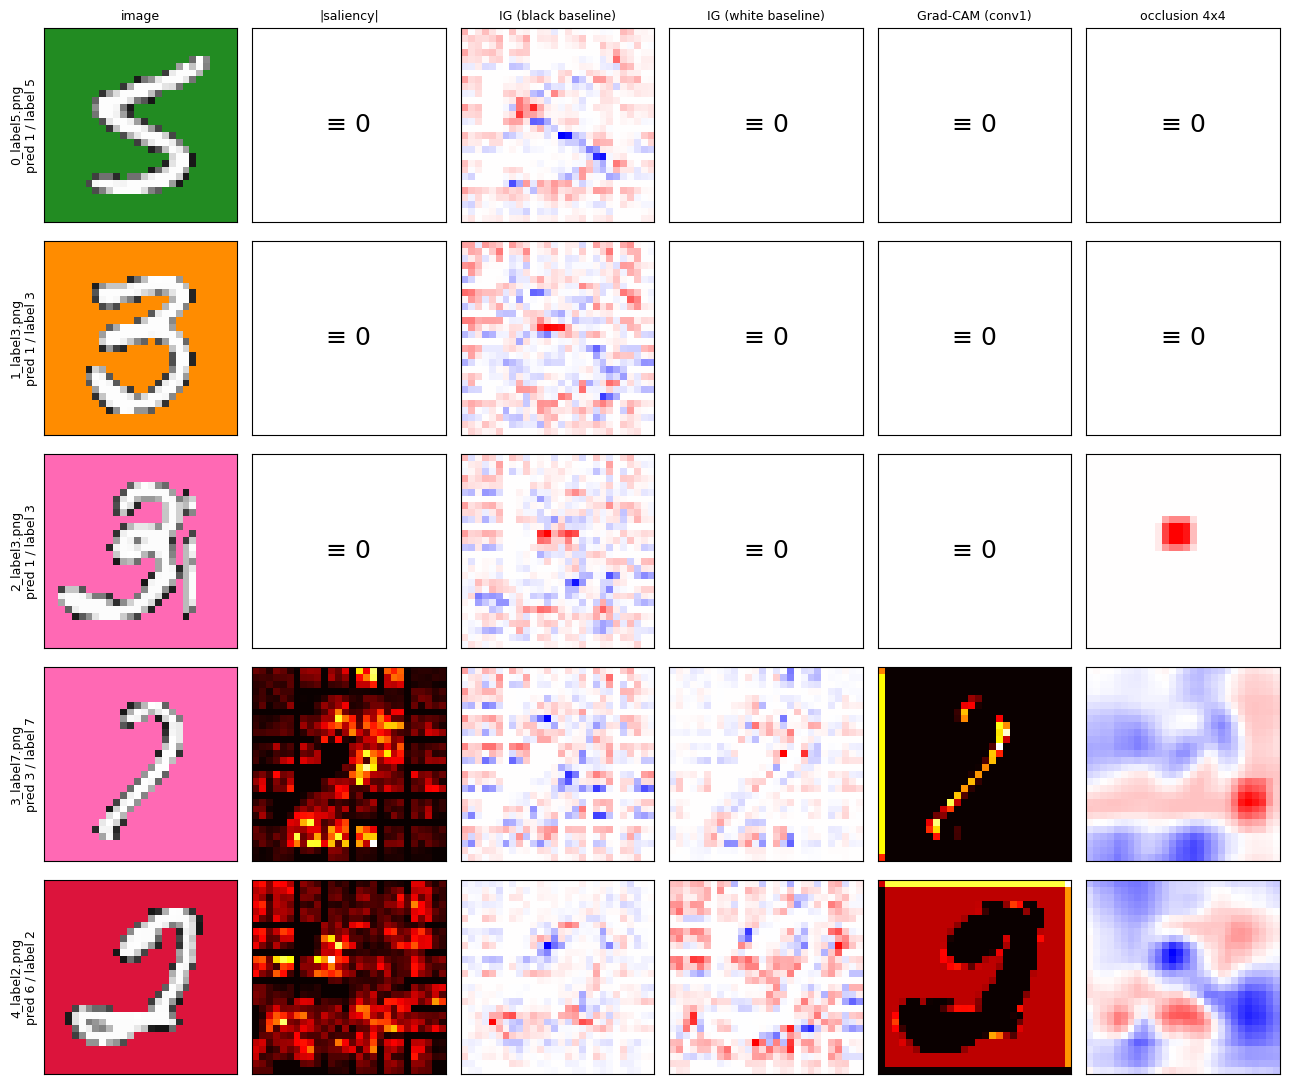

In [6]:
# ---------- 2. Classic attribution maps on the challenge images ----------
challenge_files = sorted(challenge_dir.glob('*.png'))

def saliency(x, target):
    x = x.clone().requires_grad_(True)
    cpu_model(x)[0, target].backward()
    return x.grad[0].abs().sum(0)

def integrated_gradients(x, target, baseline, steps=64):
    alphas = torch.linspace(0, 1, steps + 1)[1:].view(-1, 1, 1, 1)
    path = (baseline + alphas * (x - baseline)).requires_grad_(True)
    cpu_model(path)[:, target].sum().backward()
    return ((x - baseline) * path.grad.mean(0, keepdim=True))[0].sum(0)

def gradcam(x, target):
    feats = []
    hook = cpu_model.conv1.register_forward_hook(lambda m, i, o: feats.append(o))
    out = cpu_model(x)
    hook.remove()
    grad = torch.autograd.grad(out[0, target], feats[0])[0]
    return F.relu((grad.mean((2, 3), keepdim=True) * feats[0]).sum(1))[0].detach()

def occlusion(x, target, size=4, fill=0.0):
    with torch.no_grad():
        base = cpu_model(x)[0, target]
        heat, cnt = torch.zeros(28, 28), torch.zeros(28, 28)
        for i in range(28 - size + 1):
            for j in range(28 - size + 1):
                xo = x.clone()
                xo[..., i:i + size, j:j + size] = fill
                heat[i:i + size, j:j + size] += base - cpu_model(xo)[0, target]
                cnt[i:i + size, j:j + size] += 1
    return heat / cnt

titles = ['image', '|saliency|', 'IG (black baseline)', 'IG (white baseline)', 'Grad-CAM (conv1)', 'occlusion 4x4']
fig, axes = plt.subplots(len(challenge_files), 6, figsize=(13, 11))
for r, f in enumerate(challenge_files):
    x = to_tensor(Image.open(f).convert('RGB')).unsqueeze(0)
    label = int(f.stem[-1])
    pred = cpu_model(x).argmax().item()
    maps = [saliency(x, label), integrated_gradients(x, label, torch.zeros_like(x)),
            integrated_gradients(x, label, torch.ones_like(x)), gradcam(x, label), occlusion(x, label)]
    print(f'{f.name}: pred {pred}, label {label} | max |map|: ' +
          ', '.join(f'{t}={mp.abs().max().item():.3f}' for t, mp in zip(titles[1:], maps)))
    axes[r, 0].imshow(x[0].permute(1, 2, 0))
    axes[r, 0].set_ylabel(f'{f.name}\npred {pred} / label {label}', fontsize=9)
    for c, mp in enumerate(maps, start=1):
        v = mp.abs().max().item()
        if v < 1e-8:  # identically zero map: the model output does not depend on the input here
            axes[r, c].imshow(np.ones((28, 28)), cmap='gray', vmin=0, vmax=1)
            axes[r, c].text(13.5, 13.5, '≡ 0', ha='center', va='center', fontsize=18)
        else:
            axes[r, c].imshow(mp, cmap='hot' if c in (1, 4) else 'bwr', vmin=0 if c in (1, 4) else -v, vmax=v)
    for c, ax in enumerate(axes[r]):
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(titles[c], fontsize=9)
plt.tight_layout()
fig.savefig(report_dir / 'fig_xai_maps.png', dpi=130, bbox_inches='tight')
plt.show()

**Conclusión.** En las imágenes 0, 1 y 2 **saliency, Grad-CAM e IG con base blanca son idénticamente 0**, y la oclusión
también (salvo un parche central en la 2): el modelo es "ciego" a la imagen, su salida no cambia. Sólo IG con base negra
devuelve algo, porque en el camino desde el negro la red sí se activa (el negro se comporta como un fondo "par"). En la
imagen 4, Grad-CAM de la clase 2 se concentra en el **fondo** y no en el trazo: el color es la evidencia principal. En la 3
los mapas son ruidosos y la oclusión muestra que zonas *sin trazo* cambian la decisión: es muy frágil.
Los métodos de gradiente no sirven para guiar la edición de 0, 1 y 2 → hay que bajar a nivel de neurona.

## 3. Análisis a nivel de neurona (`fc1`, 12 unidades)

Si los gradientes son nulos es porque todas las ReLU de `fc1` están apagadas. Estudiamos qué unidades se activan,
con qué colores, y — usando los pesos de `fc2` — qué clase gana cuando sólo una unidad está activa.

In [7]:
# ---------- 3. Neuron-level analysis of fc1 ----------
a_s = F.relu(z_s)
odd_bg = np.isin(bg_s, ODD_COLORS)
print('Fraction of sample images in which each fc1 unit is active (> 0):')
print(f'{"unit":>4s} {"all":>6s} {"odd bg":>7s} {"even bg":>8s}')
for n in range(12):
    act = (a_s[:, n] > 0).numpy()
    print(f'{n:4d} {act.mean():6.3f} {act[odd_bg].mean():7.3f} {act[~odd_bg].mean():8.3f}')
dead = (a_s.sum(1) == 0).numpy()
print(f'Images with ALL fc1 units dead -> odd bg: {dead[odd_bg].mean():.3f} | even bg: {dead[~odd_bg].mean():.3f}')

b2 = cpu_model.fc2.bias.detach()
print('\nfc2 bias:', b2.numpy().round(2), '| softmax:', torch.softmax(b2, 0).numpy().round(3), '-> argmax', b2.argmax().item())

print('\nfc1 pre-activation of the alive units for a uniform image of each colour:')
print(f'{"colour":12s}', ''.join(f'{"u" + str(n):>8s}' for n in [3, 5, 7, 9, 11]))
for rgb, name in list(COLOR_NAMES.items()) + [((255, 255, 255), 'white'), ((0, 0, 0), 'black')]:
    z, _ = forward_with_fc1(to_batch([np.full((28, 28, 3), rgb, np.uint8)]))
    print(f'{name:12s}', ''.join(f'{v:8.2f}' for v in z[0, [3, 5, 7, 9, 11]].tolist()))

print('\nfc1 on the challenge images:')
for f in challenge_files:
    z, logits = forward_with_fc1(to_batch([np.array(Image.open(f).convert('RGB'))]))
    active = {n: round(v, 2) for n, v in enumerate(F.relu(z[0]).tolist()) if v > 0}
    print(f'{f.name}: pred {logits.argmax().item()} | active units {active}')

Fraction of sample images in which each fc1 unit is active (> 0):
unit    all  odd bg  even bg
   0  0.000   0.000    0.000
   1  0.000   0.000    0.000
   2  0.000   0.000    0.000
   3  0.451   0.427    0.475
   4  0.000   0.000    0.000
   5  0.219   0.001    0.444
   6  0.000   0.000    0.000
   7  0.321   0.000    0.651
   8  0.000   0.000    0.000
   9  0.324   0.001    0.658
  10  0.000   0.000    0.000
  11  0.410   0.001    0.832
Images with ALL fc1 units dead -> odd bg: 0.572 | even bg: 0.000

fc2 bias: [-1.17  1.74 -1.74  1.6  -1.91  1.45 -1.23  0.59 -0.93  0.1 ] | softmax: [0.016 0.297 0.009 0.259 0.008 0.223 0.015 0.094 0.021 0.058] -> argmax 1

fc1 pre-activation of the alive units for a uniform image of each colour:
colour             u3      u5      u7      u9     u11
forestgreen     -1.78   -8.05   -7.46  -13.36   -9.16
darkorange      -2.20  -12.53   -8.70  -19.04  -11.18
hotpink         -1.47   -8.86   -3.98  -10.64   -4.32
crimson         -2.03   -1.61    5.29    1.

In [8]:
# Single-unit "activation windows": with only unit n active (activation a >= 0, the rest 0),
# logits = b2 + W2[:, n] * a. For which values of a does each class win?
W2, B2 = cpu_model.fc2.weight.detach().numpy(), b2.numpy()

def activation_window(unit, cls):
    lo, hi = 0.0, np.inf
    for k in range(10):
        if k == cls:
            continue
        d0, d1 = B2[cls] - B2[k], W2[cls, unit] - W2[k, unit]  # need d0 + d1 * a > 0
        if d1 > 0:
            lo = max(lo, -d0 / d1)
        elif d1 < 0:
            hi = min(hi, -d0 / d1)
        elif d0 <= 0:
            return None
    return (lo, hi) if lo < hi else None

ALIVE_UNITS = [n for n in range(12) if (a_s[:, n] > 0).any()]
print('Units that activate at least once on the sample set:', ALIVE_UNITS)
for cls in sorted({int(f.stem[-1]) for f in challenge_files}):
    wins = {n: tuple(round(float(v), 2) for v in w) for n in ALIVE_UNITS if (w := activation_window(n, cls))}
    print(f'class {cls} wins alone with: {wins}')

Units that activate at least once on the sample set: [3, 5, 7, 9, 11]
class 2 wins alone with: {11: (3.01, inf)}
class 3 wins alone with: {3: (0.29, 0.96), 5: (0.17, 1.98)}
class 5 wins alone with: {7: (0.83, 2.55), 11: (0.62, 2.04)}
class 7 wins alone with: {3: (0.96, 4.24)}


**Conclusión (insights clave).**
- 7 de las 12 unidades no se activan nunca. Las unidades **5, 7, 9 y 11 son detectores de "fondo par"**: sólo se
  encienden sobre fondos carmesí/azul/violeta (≤ 0.1 % de las veces en fondos impares), su pre-activación es muy negativa
  con colores con mucha componente verde (verde, naranja, rosa… y **blanco**) y empujan en contra de todas las clases impares.
- En fondo impar, en la práctica, sólo sobrevive la **unidad 3**, y más de la mitad de las veces no hay ninguna activa ⇒ la salida es el
  sesgo de `fc2` ⇒ predice **1** (es lo que pasa en las imágenes 0, 1 y 2, con probabilidades idénticas).
- Ventanas: con la unidad 3 sola gana el **3** si a₃ ∈ (0.29, 0.96) y el **7** si a₃ ∈ (0.96, 4.24); la imagen 3 tiene
  a₃ = 0.61 → sale 3. El **5 es inalcanzable con la unidad 3**: necesita una activación *moderada* de una unidad "par"
  (7 u 11), que penaliza más al 1 y al 3 que al 5. Para que el modelo diga "5", la imagen tiene que parecer *un poco par*.
- La imagen 4 (fondo par) está en la frontera 2/6 (0.435 vs 0.455): basta con un empujón mínimo.

## 4. Edición mínima guiada por neuronas

Búsqueda voraz píxel a píxel (sin gradientes, que aquí son nulos), con píxeles restringidos a una paleta plausible
(los 6 colores de fondo + blanco + negro):
1. **Fase 1 – despertar la unidad auxiliar.** Mientras la salida es plana, en cada paso se prueba *todo* cambio de un
   píxel y se elige el que más sube la **pre-activación** (antes de la ReLU) de la unidad auxiliar: es una oclusión
   exhaustiva a nivel de neurona.
2. **Fase 2 – margen.** En cuanto la salida reacciona se maximiza `logit(etiqueta) − max(otros)` hasta superar δ = 0.05.
3. **Poda.** Se revierten uno a uno los píxeles que no hacen falta para mantener el margen.

La unidad auxiliar sale del análisis anterior: unidades vivas con ventana para la clase objetivo
(5 → {7, 11}; 3 → {3, 5}; 7 → {3}; 2 → {11}); nos quedamos con la edición de menos píxeles.

In [9]:
# ---------- 4. Neuron-guided minimal editing ----------
PALETTE = [np.array(rgb, np.uint8) for rgb in COLOR_NAMES] + [np.array(c, np.uint8) for c in [(255, 255, 255), (0, 0, 0)]]

def class_margin(logits, label):
    other = logits.clone()
    other[:, label] = -np.inf
    return (logits[:, label] - other.max(1).values).numpy()

def single_pixel_candidates(img):
    cands, where = [], []
    for i in range(28):
        for j in range(28):
            for c in PALETTE:
                if (img[i, j] != c).any():
                    new = img.copy()
                    new[i, j] = c
                    cands.append(new)
                    where.append((i, j))
    return cands, where

def prune(orig, img, label, thr):
    # revert edited pixels one at a time while the margin stays >= thr
    while True:
        idx = np.argwhere((img != orig).any(-1))
        if len(idx) == 0:
            return img
        cands = []
        for i, j in idx:
            new = img.copy()
            new[i, j] = orig[i, j]
            cands.append(new)
        m = class_margin(forward_with_fc1(to_batch(cands))[1], label)
        if m.max() < thr - 1e-6:
            return img
        img = cands[int(m.argmax())]

def neuron_guided_edit(orig, label, helper, delta=0.05, max_steps=80, patience=8):
    img, best, stall = orig.copy(), -np.inf, 0
    for _ in range(max_steps):
        z0, l0 = forward_with_fc1(to_batch([img]))
        m0 = class_margin(l0, label)[0]
        if m0 >= delta:
            break
        stall = 0 if m0 > best + 1e-5 else stall + 1
        best = max(best, m0)
        if stall > patience and best > 0:
            break
        cands, where = single_pixel_candidates(img)
        z, logits = forward_with_fc1(to_batch(cands))
        m = class_margin(logits, label)
        flat = m.max() <= m0 + 1e-6 and not (z0 > 0).any()
        score = z[:, helper].numpy() if flat else m  # phase 1: wake up the helper unit | phase 2: class margin
        score = score + 1e-4 * np.array([(img[i, j] != orig[i, j]).any() for i, j in where])  # prefer already-edited pixels
        img = cands[int(score.argmax())]
    final = class_margin(forward_with_fc1(to_batch([img]))[1], label)[0]
    return prune(orig, img, label, min(delta, final))

edited_dir = challenge_dir / 'edited'
edits = {}
for f in challenge_files:
    label = int(f.stem[-1])
    orig = np.array(Image.open(f).convert('RGB'))
    best = None
    for helper in [n for n in ALIVE_UNITS if activation_window(n, label)]:
        img = neuron_guided_edit(orig, label, helper)
        n_px = int((img != orig).any(-1).sum())
        mg = class_margin(forward_with_fc1(to_batch([img]))[1], label)[0]
        print(f'{f.name}: helper unit {helper:2d} -> {n_px:3d} pixels changed, margin {mg:+.3f}')
        if mg > 0 and (best is None or (n_px, -mg) < (best['n_px'], -best['margin'])):
            best = dict(img=img, n_px=n_px, margin=mg, helper=helper)
    edits[f.name] = best
    Image.fromarray(best['img']).save(edited_dir / f.name)

0_label5.png: helper unit  7 ->  19 pixels changed, margin +0.068


0_label5.png: helper unit 11 ->  20 pixels changed, margin +0.125


1_label3.png: helper unit  3 ->   6 pixels changed, margin +0.086


1_label3.png: helper unit  5 ->  22 pixels changed, margin +0.051


2_label3.png: helper unit  3 ->   6 pixels changed, margin +0.086


2_label3.png: helper unit  5 ->  11 pixels changed, margin +0.219


3_label7.png: helper unit  3 ->   1 pixels changed, margin +0.338


4_label2.png: helper unit 11 ->   1 pixels changed, margin +1.001


image          helper changed px preserved pred  margin    bf16 noise min  active fc1 units


0_label5.png        7         19    97.58%    5  +0.068  +0.056    +0.048  {7: 1.03}


1_label3.png        3          6    99.23%    3  +0.086  +0.072    +0.060  {3: 0.48}


2_label3.png        3          6    99.23%    3  +0.086  +0.081    +0.065  {3: 0.48}


3_label7.png        3          1    99.87%    7  +0.338  +0.328    +0.313  {3: 1.3}


4_label2.png       11          1    99.87%    2  +1.001  +0.980    +0.938  {5: 2.33, 7: 12.28, 11: 5.46}


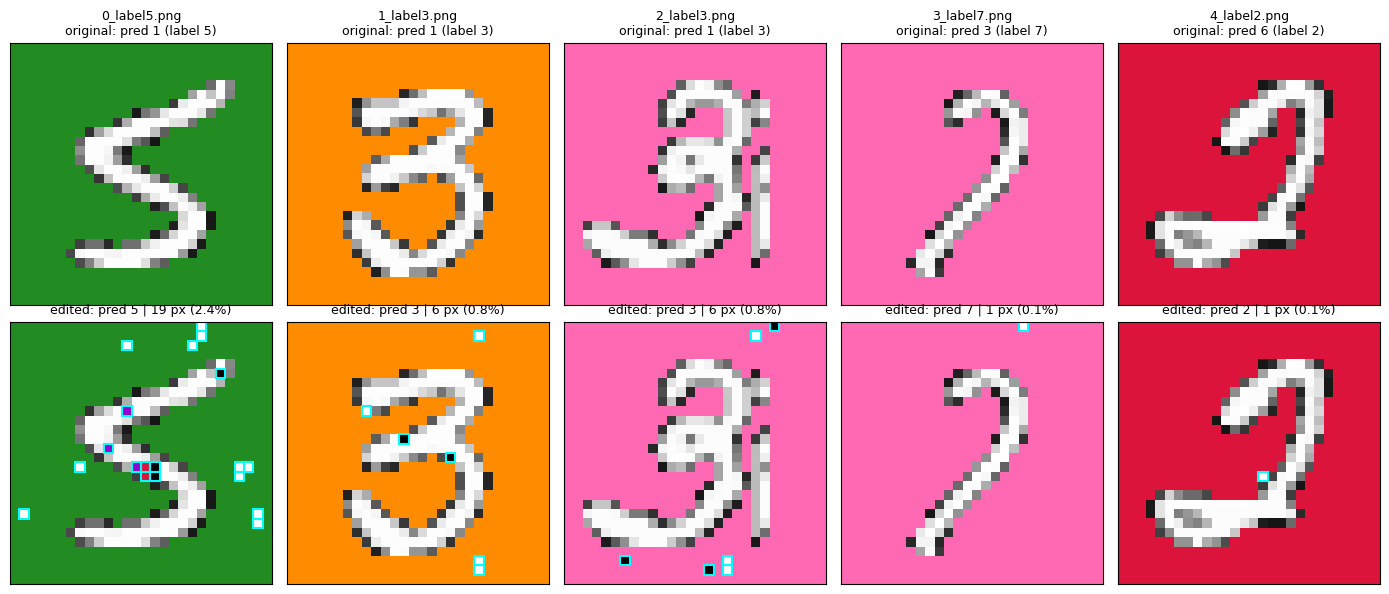

In [10]:
# Summary, robustness check and figure of the final edits
def margin_variants(img, label, n_trials=200, eps=2e-3):
    # fp64, bf16-rounded forward pass (coarser than the TF32 used by GPUs) and random weight noise
    x = to_batch([img])
    r = lambda t: t.to(torch.bfloat16).float()
    with torch.no_grad():
        fp64 = class_margin(copy.deepcopy(cpu_model).double()(x.double()), label)[0]
        h = cpu_model.pool(cpu_model.pool(r(F.relu(F.conv2d(r(x), r(cpu_model.conv1.weight), r(cpu_model.conv1.bias), padding=1)))))
        h = r(F.relu(F.linear(h.reshape(1, -1), r(cpu_model.fc1.weight), r(cpu_model.fc1.bias))))
        bf16 = class_margin(F.linear(h, r(cpu_model.fc2.weight), r(cpu_model.fc2.bias)), label)[0]
        g, worst = torch.Generator().manual_seed(0), np.inf
        for _ in range(n_trials):
            noisy = copy.deepcopy(cpu_model)
            for p in noisy.parameters():
                p.mul_(1 + eps * torch.randn(p.shape, generator=g))
            worst = min(worst, class_margin(noisy(x), label)[0])
    return fp64, bf16, worst

print(f'{"image":14s} {"helper":>6s} {"changed px":>10s} {"preserved":>9s} {"pred":>4s} {"margin":>7s} {"bf16":>7s} {"noise min":>9s}  active fc1 units')
for f in challenge_files:
    e, label = edits[f.name], int(f.stem[-1])
    z, logits = forward_with_fc1(to_batch([e['img']]))
    fp64, bf16, worst = margin_variants(e['img'], label)
    active = {n: round(v, 2) for n, v in enumerate(F.relu(z[0]).tolist()) if v > 0}
    print(f'{f.name:14s} {e["helper"]:6d} {e["n_px"]:10d} {100 - 100 * e["n_px"] / 784:8.2f}% {logits.argmax().item():4d} '
          f'{fp64:+7.3f} {bf16:+7.3f} {worst:+9.3f}  {active}')

fig, axes = plt.subplots(2, len(challenge_files), figsize=(14, 6))
for c, f in enumerate(challenge_files):
    orig = np.array(Image.open(f).convert('RGB'))
    e, label = edits[f.name], int(f.stem[-1])
    p_orig = cpu_model(to_batch([orig])).argmax().item()
    p_edit = cpu_model(to_batch([e['img']])).argmax().item()
    axes[0, c].imshow(orig)
    axes[0, c].set_title(f'{f.name}\noriginal: pred {p_orig} (label {label})', fontsize=9)
    axes[1, c].imshow(e['img'])
    for i, j in np.argwhere((e['img'] != orig).any(-1)):
        axes[1, c].add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec='cyan', lw=1.5))
    axes[1, c].set_title(f'edited: pred {p_edit} | {e["n_px"]} px ({100 * e["n_px"] / 784:.1f}%)', fontsize=9)
    for ax in axes[:, c]:
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
fig.savefig(report_dir / 'fig_edits.png', dpi=130, bbox_inches='tight')
plt.show()

In [11]:
# Why does each edit work? Unit that explains the flip, leave-one-out of every edited pixel on that unit,
# and the 7x7 pooling cells through which the change enters it.
W1 = cpu_model.fc1.weight.detach().reshape(12, 12, 7, 7)

def pooled(img):
    with torch.no_grad():
        return cpu_model.pool(cpu_model.pool(F.relu(cpu_model.conv1(to_batch([img])))))[0]

for f in challenge_files:
    e, label = edits[f.name], int(f.stem[-1])
    orig = np.array(Image.open(f).convert('RGB'))
    (z0, l0), (z1, _) = forward_with_fc1(to_batch([orig])), forward_with_fc1(to_batch([e['img']]))
    old_pred = l0.argmax().item()
    # contribution of each unit to the change of logit(label) - logit(old prediction)
    contrib = (F.relu(z1[0]) - F.relu(z0[0])) * torch.from_numpy(W2[label] - W2[old_pred])
    key = contrib.argmax().item()
    loo = []
    for i, j in np.argwhere((e['img'] != orig).any(-1)):
        rev = e['img'].copy()
        rev[i, j] = orig[i, j]
        loo.append(z1[0, key].item() - forward_with_fc1(to_batch([rev]))[0][0, key].item())
    cells = ((pooled(e['img']) - pooled(orig)) * W1[key]).sum(0)
    top = sorted(((cells[i, j].item(), i, j) for i in range(7) for j in range(7)), reverse=True)[:3]
    print(f'{f.name}: {old_pred} -> {label} | key unit {key}: pre-act {z0[0, key]:+.2f} -> {z1[0, key]:+.2f} '
          f'(+{contrib[key]:.2f} to the margin vs {old_pred}) | {int((cells != 0).sum())} cells touched, '
          f'top cells {[(i, j, round(v, 2)) for v, i, j in top]} | every pixel adds {min(loo):+.2f}..{max(loo):+.2f}')

0_label5.png: 1 -> 5 | key unit 7: pre-act -10.64 -> +1.03 (+0.36 to the margin vs 1) | 22 cells touched, top cells [(0, 4, 1.56), (3, 3, 1.51), (4, 3, 1.05)] | every pixel adds +0.42..+1.35
1_label3.png: 1 -> 3 | key unit 3: pre-act -3.93 -> +0.48 (+0.22 to the margin vs 1) | 10 cells touched, top cells [(6, 4, 1.38), (0, 4, 0.64), (3, 4, 0.5)] | every pixel adds +0.50..+0.92
2_label3.png: 1 -> 3 | key unit 3: pre-act -3.26 -> +0.48 (+0.22 to the margin vs 1) | 5 cells touched, top cells [(6, 4, 1.79), (6, 1, 0.69), (0, 5, 0.59)] | every pixel adds +0.27..+1.17
3_label7.png: 3 -> 7 | key unit 3: pre-act +0.61 -> +1.30 (+0.73 to the margin vs 3) | 2 cells touched, top cells [(0, 4, 0.51), (0, 5, 0.18), (6, 6, 0.0)] | every pixel adds +0.69..+0.69
4_label2.png: 6 -> 2 | key unit 5: pre-act +1.23 -> +2.33 (+0.86 to the margin vs 6) | 4 cells touched, top cells [(3, 3, 0.68), (4, 3, 0.21), (4, 4, 0.11)] | every pixel adds +1.10..+1.10


**Resultado.** Las cinco imágenes pasan a clasificarse correctamente cambiando entre 1 y 19 píxeles (se conserva ≥ 97.5 %
de los píxeles, muy por encima del 60 % exigido). El *leave-one-out* (revertir cada píxel editado y medir la unidad clave)
confirma que todos los píxeles aportan y explica cada edición:
- **0 (5):** 19 píxeles repartidos por toda la imagen (afectan a 22 de las 49 celdas de max-pooling; con un max-pool 4×4
  basta un píxel por celda para subir su máximo): puntos blancos aislados sobre el fondo y píxeles violeta/carmesí/negro sobre el trazo.
  La unidad "par" 7 pasa de −10.6 a **a₇ = 1.03**, dentro de su ventana (0.83, 2.55) para el 5.
- **1 y 2 (3):** 6 píxeles que llevan la unidad 3 a **a₃ = 0.48**, dentro de la ventana (0.29, 0.96) del 3. La mayor
  contribución entra por la celda (6, 4) de la fila inferior, donde la unidad 3 tiene sus pesos positivos más altos.
- **3 (7):** un único píxel blanco en el borde superior, en la celda (0, 4) donde la unidad 3 tiene un peso alto:
  a₃ sube de 0.61 a **1.30 > 0.96** y el 7 supera al 3.
- **4 (2):** un único píxel blanco de fondo junto al trazo, en el centro: la unidad 5 (cuyo peso en `fc2` favorece al 2
  frente al 6 en +0.78) pasa de 1.23 a 2.33 y el 2 gana con margen 1.0.

Las predicciones se mantienen con aritmética bf16 (más gruesa que el TF32 que usan las GPU) y con ruido del 0.2 % en los
pesos, así que no dependen de ejecutar en CPU o GPU.

---
## Check if you have passed the challenge 

In [12]:
# Check percentage of editing an image
def calculate_edit_percentage(original_img, edited_img):
    original_pixels = original_img.load()
    edited_pixels = edited_img.load()
    width, height = original_img.size
    total_pixels = width * height
    changed_pixels = 0

    for x in range(width):
        for y in range(height):
            if original_pixels[x, y] != edited_pixels[x, y]:
                changed_pixels += 1

    return (changed_pixels / total_pixels) * 100

In [13]:
# Create edited directory
edited_dir = challenge_dir / 'edited'

# Load edited images, check that they are predicted correctly and calculate edit percentages
for original_img_file, edited_img_file in zip(challenge_dir.glob('*.png'), edited_dir.glob('*.png')):
    original_img = Image.open(original_img_file)
    edited_img = Image.open(edited_img_file)
    # Convert the edited image to RGB if it's not
    if edited_img.mode != 'RGB':
        edited_img = edited_img.convert('RGB')

    # Check prediction
    img_tensor = to_tensor(edited_img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img_tensor)
        pred = output.argmax(dim=1).item()
    
    print(f'Edited {edited_img_file.name}: Pred: {pred}, Label: {original_img_file.stem[-1]}, correct: {pred == int(original_img_file.stem[-1])}')

    # Calculate edit percentage
    edit_percentage = calculate_edit_percentage(original_img, edited_img)
    print(f'Edit Percentage: {edit_percentage:.2f}%')


Edited 0_label5.png: Pred: 5, Label: 5, correct: True
Edit Percentage: 2.42%
Edited 1_label3.png: Pred: 3, Label: 3, correct: True
Edit Percentage: 0.77%
Edited 2_label3.png: Pred: 3, Label: 3, correct: True
Edit Percentage: 0.77%
Edited 3_label7.png: Pred: 7, Label: 7, correct: True
Edit Percentage: 0.13%
Edited 4_label2.png: Pred: 2, Label: 2, correct: True
Edit Percentage: 0.13%
